## Dados do Brasileirão de pontos corridos 2007 à 2025

Neste estudo de caso realizamos uma análise exploratória e estatística dos dados históricos do Campeonato Brasileiro para investigar fatores que influenciam o sucesso das equipes. O projeto tem três dashboards:

1. **Desempenho do Campeão** — análise da trajetória dos campeões ao longo do campeonato
2. **Investimento vs Títulos** — correlação valor de mercado × desempenho final, com inferência estatística
3. **Tese da 8ª Rodada** — testar se um bom início de campeonato correlaciona com o título, com correlação em 3 períodos (população completa, 2007-2017, 2018-2025)

## ETL base

Nesta sessão vou fazer a etl para ter um df base

### Instalação de pacotes

In [1]:
!pip install -q missingno
#com ele conseguimos criar um mapa de valores ausentes 

In [2]:
!pip install -q category_encoders
#permite categorizar as variaveis

In [3]:
!pip install -q plotly
#este pacote cria graficos 

In [4]:
!pip install matplotlib

In [5]:
# importando bibliotecas para o projeto
# Imports

# Manipulação de dados
import pandas as pd
import numpy as np

# Visualização
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import missingno

# Estatística
import scipy
from scipy.stats import normaltest
from scipy.stats import chi2_contingency

# Engenharia de Atributos
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
import category_encoders as ce

# Ignore Warning
import sys
import warnings
if not sys.warnoptions:
    warnings.simplefilter("ignore")

In [6]:
!pip install -q -U watermark

In [7]:
%reload_ext watermark
%watermark -a "Renato"

Author: Renato



In [8]:
# Configuração para os gráficos aparecerem bem no Jupyter
%matplotlib inline
sns.set_theme(style="whitegrid")

In [9]:
#carregando os dados 
df = pd.read_csv('../dados/raw/Campeonato.csv')

In [10]:
df.head()

,ano_campeonato,data,rodada,estadio,arbitro,publico,publico_max,time_mandante,time_visitante,tecnico_mandante,...,chutes_bola_parada_mandante,chutes_bola_parada_visitante,defesas_mandante,defesas_visitante,impedimentos_mandante,impedimentos_visitante,chutes_mandante,chutes_visitante,chutes_fora_mandante,chutes_fora_visitante
0,2005,2005-10-08,31,Estádio Durival Britto e Silva,NaN,NaN,NaN,Paraná,Fluminense,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2005,2005-04-23,1,Estádio Durival Britto e Silva,NaN,NaN,NaN,Paraná,Goiás EC,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2005,2005-08-21,21,Estádio Durival Britto e Silva,NaN,NaN,NaN,Paraná,Vasco da Gama,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2005,2005-08-28,23,Estádio Durival Britto e Silva,NaN,NaN,NaN,Paraná,São Paulo,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2005,2005-06-26,9,Estádio Olímpico Nilton Santos,NaN,NaN,NaN,Botafogo,Figueirense FC,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
#como o ano em que o campeonato foi composto por 20 times foi 2006, vou retirar os anos anteriores, para que fique uma análise mais justa 
df = df[df['ano_campeonato'] >= 2007].copy()

In [12]:
df.head()

,ano_campeonato,data,rodada,estadio,arbitro,publico,publico_max,time_mandante,time_visitante,tecnico_mandante,...,chutes_bola_parada_mandante,chutes_bola_parada_visitante,defesas_mandante,defesas_visitante,impedimentos_mandante,impedimentos_visitante,chutes_mandante,chutes_visitante,chutes_fora_mandante,chutes_fora_visitante
418,2016,2016-09-15,25,Estádio Olímpico Nilton Santos,Paulo Henrique Schleinch Vollkopf,11883.0,46931.0,Botafogo,Santos FC,Jair Ventura,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
419,2016,2016-09-25,27,Estádio Estadual Kléber José de Andrade,Leandro Pedro Vuaden,13780.0,NaN,Flamengo,Cruzeiro,Zé Ricardo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
420,2016,2016-10-09,29,Estádio Municipal Paulo Machado de Carvalho,Ricardo Marques Ribeiro,21773.0,78838.0,Flamengo,Santa Cruz,Zé Ricardo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
421,2016,2016-10-23,32,Estádio Jornalista Mário Filho,Anderson Daronco,54250.0,78838.0,Flamengo,Corinthians,Zé Ricardo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
422,2016,2016-10-13,30,Estádio General Sílvio Raulino de Oliveira,Sandro Ricci,9008.0,NaN,Fluminense,Flamengo,Levir Culpi,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
# "vendo" o corpo do df após o filtro
df.shape

(6743, 35)

In [14]:
#conferindo as colunas 
df.columns

Index(['ano_campeonato', 'data', 'rodada', 'estadio', 'arbitro', 'publico',
       'publico_max', 'time_mandante', 'time_visitante', 'tecnico_mandante',
       'tecnico_visitante', 'colocacao_mandante', 'colocacao_visitante',
       'valor_equipe_titular_mandante', 'valor_equipe_titular_visitante',
       'idade_media_titular_mandante', 'idade_media_titular_visitante',
       'gols_mandante', 'gols_visitante', 'gols_1_tempo_mandante',
       'gols_1_tempo_visitante', 'escanteios_mandante', 'escanteios_visitante',
       'faltas_mandante', 'faltas_visitante', 'chutes_bola_parada_mandante',
       'chutes_bola_parada_visitante', 'defesas_mandante', 'defesas_visitante',
       'impedimentos_mandante', 'impedimentos_visitante', 'chutes_mandante',
       'chutes_visitante', 'chutes_fora_mandante', 'chutes_fora_visitante'],
      dtype='object')

### Análise exploratória

  Aqui vou saber como o interpretador "classificou" as colunas 

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6743 entries, 418 to 8452
Data columns (total 35 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   ano_campeonato                  6743 non-null   int64  
 1   data                            6743 non-null   object 
 2   rodada                          6743 non-null   int64  
 3   estadio                         6732 non-null   object 
 4   arbitro                         6743 non-null   object 
 5   publico                         6742 non-null   float64
 6   publico_max                     4181 non-null   float64
 7   time_mandante                   6743 non-null   object 
 8   time_visitante                  6743 non-null   object 
 9   tecnico_mandante                6299 non-null   object 
 10  tecnico_visitante               6299 non-null   object 
 11  colocacao_mandante              6743 non-null   float64
 12  colocacao_visitante             6743 

In [16]:
df.tail()

,ano_campeonato,data,rodada,estadio,arbitro,publico,publico_max,time_mandante,time_visitante,tecnico_mandante,...,chutes_bola_parada_mandante,chutes_bola_parada_visitante,defesas_mandante,defesas_visitante,impedimentos_mandante,impedimentos_visitante,chutes_mandante,chutes_visitante,chutes_fora_mandante,chutes_fora_visitante
8448,2017,2017-10-15,28,Estádio Municipal Paulo Machado de Carvalho,Marcelo de Lima Henrique,26833.0,37730.0,São Paulo,Atlético-PR,Dorival Júnior,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8449,2017,2017-10-22,30,Estádio Municipal Paulo Machado de Carvalho,Rafael Traci,32965.0,37730.0,São Paulo,Flamengo,Dorival Júnior,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8450,2017,2017-10-28,31,Estádio Municipal Paulo Machado de Carvalho,Anderson Daronco,40004.0,40500.0,São Paulo,Santos FC,Dorival Júnior,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8451,2017,2017-11-09,33,Estádio Municipal Paulo Machado de Carvalho,Marcelo de Lima Henrique,35037.0,37730.0,São Paulo,Chapecoense,Dorival Júnior,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8452,2017,2017-11-19,36,Estádio Municipal Paulo Machado de Carvalho,Wilton Sampaio,25771.0,37730.0,São Paulo,Botafogo,Dorival Júnior,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
# verificando as colunas vazias
df.isna().sum().sort_values(ascending=False)

chutes_fora_visitante             4656
impedimentos_mandante             4656
escanteios_visitante              4656
escanteios_mandante               4656
chutes_bola_parada_mandante       4656
chutes_bola_parada_visitante      4656
faltas_visitante                  4656
defesas_visitante                 4656
defesas_mandante                  4656
impedimentos_visitante            4656
chutes_mandante                   4656
chutes_visitante                  4656
chutes_fora_mandante              4656
faltas_mandante                   4656
publico_max                       2562
tecnico_mandante                   444
tecnico_visitante                  444
idade_media_titular_mandante       390
idade_media_titular_visitante      390
valor_equipe_titular_mandante      388
valor_equipe_titular_visitante     388
gols_1_tempo_mandante               11
gols_1_tempo_visitante              11
estadio                             11
gols_mandante                        1
gols_visitante           

In [18]:
# excluindo as com poucos valores ou totalmente vazias
df = df.drop(columns=[
    'impedimentos_mandante',
    'impedimentos_visitante',
    'defesas_mandante',
    'chutes_mandante',
    'chutes_visitante',
    'chutes_fora_mandante'
])

In [19]:
df.head()

,ano_campeonato,data,rodada,estadio,arbitro,publico,publico_max,time_mandante,time_visitante,tecnico_mandante,...,gols_1_tempo_mandante,gols_1_tempo_visitante,escanteios_mandante,escanteios_visitante,faltas_mandante,faltas_visitante,chutes_bola_parada_mandante,chutes_bola_parada_visitante,defesas_visitante,chutes_fora_visitante
418,2016,2016-09-15,25,Estádio Olímpico Nilton Santos,Paulo Henrique Schleinch Vollkopf,11883.0,46931.0,Botafogo,Santos FC,Jair Ventura,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
419,2016,2016-09-25,27,Estádio Estadual Kléber José de Andrade,Leandro Pedro Vuaden,13780.0,NaN,Flamengo,Cruzeiro,Zé Ricardo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
420,2016,2016-10-09,29,Estádio Municipal Paulo Machado de Carvalho,Ricardo Marques Ribeiro,21773.0,78838.0,Flamengo,Santa Cruz,Zé Ricardo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
421,2016,2016-10-23,32,Estádio Jornalista Mário Filho,Anderson Daronco,54250.0,78838.0,Flamengo,Corinthians,Zé Ricardo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
422,2016,2016-10-13,30,Estádio General Sílvio Raulino de Oliveira,Sandro Ricci,9008.0,NaN,Fluminense,Flamengo,Levir Culpi,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Desempenho do Campeão

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6743 entries, 418 to 8452
Data columns (total 29 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   ano_campeonato                  6743 non-null   int64  
 1   data                            6743 non-null   object 
 2   rodada                          6743 non-null   int64  
 3   estadio                         6732 non-null   object 
 4   arbitro                         6743 non-null   object 
 5   publico                         6742 non-null   float64
 6   publico_max                     4181 non-null   float64
 7   time_mandante                   6743 non-null   object 
 8   time_visitante                  6743 non-null   object 
 9   tecnico_mandante                6299 non-null   object 
 10  tecnico_visitante               6299 non-null   object 
 11  colocacao_mandante              6743 non-null   float64
 12  colocacao_visitante             6743 

In [21]:
# Ajustando o recorte para 2007 devido à ausência de dados financeiros em 2006 e criando a coluna temporada devido ao ano de 2020 em que 
# o campeonato terminou no início de 2021
df['data'] = pd.to_datetime(df['data'])
df['temporada'] = df['data'].dt.year
mask_2020_prolongado = (df['data'] >= '2021-01-01') & (df['data'] <= '2021-02-25')
df.loc[mask_2020_prolongado, 'temporada'] = 2020

df = df[df['temporada'] >= 2007].copy()

In [22]:
df.head()

,ano_campeonato,data,rodada,estadio,arbitro,publico,publico_max,time_mandante,time_visitante,tecnico_mandante,...,gols_1_tempo_visitante,escanteios_mandante,escanteios_visitante,faltas_mandante,faltas_visitante,chutes_bola_parada_mandante,chutes_bola_parada_visitante,defesas_visitante,chutes_fora_visitante,temporada
418,2016,2016-09-15,25,Estádio Olímpico Nilton Santos,Paulo Henrique Schleinch Vollkopf,11883.0,46931.0,Botafogo,Santos FC,Jair Ventura,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2016
419,2016,2016-09-25,27,Estádio Estadual Kléber José de Andrade,Leandro Pedro Vuaden,13780.0,NaN,Flamengo,Cruzeiro,Zé Ricardo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2016
420,2016,2016-10-09,29,Estádio Municipal Paulo Machado de Carvalho,Ricardo Marques Ribeiro,21773.0,78838.0,Flamengo,Santa Cruz,Zé Ricardo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2016
421,2016,2016-10-23,32,Estádio Jornalista Mário Filho,Anderson Daronco,54250.0,78838.0,Flamengo,Corinthians,Zé Ricardo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2016
422,2016,2016-10-13,30,Estádio General Sílvio Raulino de Oliveira,Sandro Ricci,9008.0,NaN,Fluminense,Flamengo,Levir Culpi,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2016


In [23]:
df.columns

Index(['ano_campeonato', 'data', 'rodada', 'estadio', 'arbitro', 'publico',
       'publico_max', 'time_mandante', 'time_visitante', 'tecnico_mandante',
       'tecnico_visitante', 'colocacao_mandante', 'colocacao_visitante',
       'valor_equipe_titular_mandante', 'valor_equipe_titular_visitante',
       'idade_media_titular_mandante', 'idade_media_titular_visitante',
       'gols_mandante', 'gols_visitante', 'gols_1_tempo_mandante',
       'gols_1_tempo_visitante', 'escanteios_mandante', 'escanteios_visitante',
       'faltas_mandante', 'faltas_visitante', 'chutes_bola_parada_mandante',
       'chutes_bola_parada_visitante', 'defesas_visitante',
       'chutes_fora_visitante', 'temporada'],
      dtype='object')

In [24]:
#criando uma lógica para calcular os pontos 
df['pts_mandante'] = np.where(
    df['gols_mandante'] > df['gols_visitante'], 3,
    np.where(df['gols_mandante'] == df['gols_visitante'], 1, 0)
)

df['pts_visitante'] = np.where(
    df['gols_visitante'] > df['gols_mandante'], 3,
    np.where(df['gols_visitante'] == df['gols_mandante'], 1, 0)
)

In [25]:
# Como vou usar no bi vou tratar esse df criando uma cópia como tabela fato ###

cols_base =[
    'data', 'rodada', 'temporada',
    'time_mandante', 'time_visitante',
    'gols_mandante', 'gols_visitante',
    'pts_mandante', 'pts_visitante'
]
df_base = df[cols_base].copy() 

In [26]:
df_base.head()

,data,rodada,temporada,time_mandante,time_visitante,gols_mandante,gols_visitante,pts_mandante,pts_visitante
418,2016-09-15,25,2016,Botafogo,Santos FC,0.0,1.0,0,3
419,2016-09-25,27,2016,Flamengo,Cruzeiro,2.0,1.0,3,0
420,2016-10-09,29,2016,Flamengo,Santa Cruz,3.0,0.0,3,0
421,2016-10-23,32,2016,Flamengo,Corinthians,2.0,2.0,1,1
422,2016-10-13,30,2016,Fluminense,Flamengo,1.0,2.0,0,3


In [27]:
  # renomeando as colunas 
df_mandante = df_base.rename(columns={
    'time_mandante': 'time',
    'time_visitante': 'adversario',
    'gols_mandante': 'gols_pro',
    'gols_visitante': 'gols_contra',
    'pts_mandante': 'pontos'
})[
    ['data', 'rodada', 'temporada', 'time', 'adversario', 'gols_pro', 'gols_contra', 'pontos']
].copy()

df_mandante['casa_fora'] = 'Casa'

In [28]:
df_visitante = df_base.rename(columns={
    'time_visitante': 'time',
    'time_mandante': 'adversario',
    'gols_visitante': 'gols_pro',
    'gols_mandante': 'gols_contra',
    'pts_visitante': 'pontos'
})[
    ['data', 'rodada', 'temporada', 'time', 'adversario', 'gols_pro', 'gols_contra', 'pontos']
].copy()

df_visitante['casa_fora'] = 'Fora'

In [29]:
#concatenando as tabelas 
df_fato = pd.concat([df_mandante, df_visitante], ignore_index=True)


In [30]:
df_fato.head()

,data,rodada,temporada,time,adversario,gols_pro,gols_contra,pontos,casa_fora
0,2016-09-15,25,2016,Botafogo,Santos FC,0.0,1.0,0,Casa
1,2016-09-25,27,2016,Flamengo,Cruzeiro,2.0,1.0,3,Casa
2,2016-10-09,29,2016,Flamengo,Santa Cruz,3.0,0.0,3,Casa
3,2016-10-23,32,2016,Flamengo,Corinthians,2.0,2.0,1,Casa
4,2016-10-13,30,2016,Fluminense,Flamengo,1.0,2.0,0,Casa


In [31]:
# verificando valores ausentes nas colunas
df_fato.isna().sum()

data           0
rodada         0
temporada      0
time           0
adversario     0
gols_pro       2
gols_contra    2
pontos         0
casa_fora      0
dtype: int64

In [32]:
# Preenchendo valor nulo, como a mostra é somente de 2 linhas com valores nulos vou substituir por 0
df_fato[['gols_pro', 'gols_contra']] = df_fato[['gols_pro', 'gols_contra']].fillna(0)

In [33]:
#criando a coluna saldo
df_fato['saldo'] = df_fato['gols_pro'] - df_fato['gols_contra']

In [34]:
# um outro problema é que as colunas gols_pro e gols_contra estão como float, e pode gerar problemas nos cálculos de saldo por exemplo,
# vou converter para int e assim criar uma coluna de saldo que funcione no bi

df_fato['gols_pro']= df_fato['gols_pro'].astype(int)
df_fato['gols_contra']= df_fato['gols_contra'].astype(int)
df_fato['saldo']= df_fato['saldo'].astype(int)

In [35]:
# criando as métricas dos pontos 


df_fato['vitoria'] = (df_fato['pontos'] == 3).astype(int)
df_fato['empate'] = (df_fato['pontos'] == 1).astype(int)
df_fato['derrota'] = (df_fato['pontos'] == 0).astype(int)

In [36]:
df_fato.head()

,data,rodada,temporada,time,adversario,gols_pro,gols_contra,pontos,casa_fora,saldo,vitoria,empate,derrota
0,2016-09-15,25,2016,Botafogo,Santos FC,0,1,0,Casa,-1,0,0,1
1,2016-09-25,27,2016,Flamengo,Cruzeiro,2,1,3,Casa,1,1,0,0
2,2016-10-09,29,2016,Flamengo,Santa Cruz,3,0,3,Casa,3,1,0,0
3,2016-10-23,32,2016,Flamengo,Corinthians,2,2,1,Casa,0,0,1,0
4,2016-10-13,30,2016,Fluminense,Flamengo,1,2,0,Casa,-1,0,0,1


In [37]:
# para ficar mais correto vou inverter a ordem das colunas rodada e temporada
df_fato = df_fato.sort_values(['temporada', 'rodada'])

In [38]:
# calculando os pontos acumulados de cada time
df_fato['pontos_acum'] = df_fato.groupby(['temporada', 'time'])['pontos'].cumsum()
df_fato['vitorias_acum'] = df_fato.groupby(['temporada', 'time']) ['vitoria'].cumsum()
df_fato['saldo_acum'] = df_fato.groupby(['temporada', 'time']) ['saldo'].cumsum()


# agora posso criar a lógica para a posição na rodada(o que vai ser útil no bi)
df_fato['posicao_rodada'] = (
    df_fato
    .sort_values(
        ['temporada', 'rodada', 'pontos_acum', 'vitorias_acum', 'saldo_acum'],
        ascending=[True, True, False, False, False]
    )
    .groupby(['temporada', 'rodada'])
    .cumcount() + 1
)

In [39]:
df_fato.head()

,data,rodada,temporada,time,adversario,gols_pro,gols_contra,pontos,casa_fora,saldo,vitoria,empate,derrota,pontos_acum,vitorias_acum,saldo_acum,posicao_rodada
5647,2007-05-03,1,2007,Internacional,Botafogo,2,3,0,Casa,-1,0,0,1,0,0,-1,12
5720,2007-05-03,1,2007,Figueirense FC,Atlético-PR,3,6,0,Casa,-3,0,0,1,0,0,-3,18
5762,2007-05-03,1,2007,Paraná,Grêmio,3,0,3,Casa,3,1,0,0,3,1,3,1
5798,2007-05-03,1,2007,Flamengo,Palmeiras,2,4,0,Casa,-2,0,0,1,0,0,-2,16
5814,2007-05-03,1,2007,Fluminense,Cruzeiro,2,2,1,Casa,0,0,1,0,1,0,0,10


In [40]:
df_fato.columns

Index(['data', 'rodada', 'temporada', 'time', 'adversario', 'gols_pro',
       'gols_contra', 'pontos', 'casa_fora', 'saldo', 'vitoria', 'empate',
       'derrota', 'pontos_acum', 'vitorias_acum', 'saldo_acum',
       'posicao_rodada'],
      dtype='object')

### Inserindo dados de outra fonte

  O dataset usado não está completo, não possui as últimas rodadas da temporada de 2024 e a temporada de 2025

In [41]:
# Lendo os novos arquivos 
df_gols = pd.read_csv('../dados/raw/campeonato-brasileiro-gols.csv')
df_full = pd.read_csv('../dados/raw/campeonato-brasileiro-full.csv')

In [42]:
#padronizando a nomenclatura das colunas 
df_gols.columns = df_gols.columns.str.lower().str.strip()
df_full.columns = df_full.columns.str.lower().str.strip()

In [43]:
#renomeando as colunas para padronizar 
df_gols = df_gols.rename(columns={'rodata': 'rodada'})
df_full = df_full.rename(columns={'rodata': 'rodada'})

In [44]:
df_gols_count = df_gols.groupby(['partida_id', 'clube']).size().reset_index(name='gols')

In [45]:
#criando a regra para mandante 
mandante = df_full.merge(
    df_gols_count,
    left_on=['id', 'mandante'],
    right_on=['partida_id', 'clube'],
    how='left'
)

mandante['gols_pro'] = mandante['gols'].fillna(0)

In [46]:
#regra para o visitante
visitante = df_full.merge(
    df_gols_count,
    left_on=['id', 'visitante'],
    right_on=['partida_id', 'clube'],
    how='left'
)

visitante['gols_pro'] = visitante['gols'].fillna(0)

In [47]:
#convertendo colunas 
df_full['gols_mandante'] = mandante['gols_pro']
df_full['gols_visitante'] = visitante['gols_pro']

In [48]:
#criando a tabela de mandante 
mandante_df = df_full[['data','rodada','mandante','visitante','gols_mandante','gols_visitante']].copy()

mandante_df.columns = ['data','rodada','time','adversario','gols_pro','gols_contra']
mandante_df['casa_fora'] = 'casa'

In [49]:
#criando a tabela de visitante 
visitante_df = df_full[['data','rodada','visitante','mandante','gols_visitante','gols_mandante']].copy()

visitante_df.columns = ['data','rodada','time','adversario','gols_pro','gols_contra']
visitante_df['casa_fora'] = 'fora'

In [50]:
#concatenando as tabelas
df_novo = pd.concat([mandante_df, visitante_df], ignore_index=True)

In [51]:
#convertendo as colunas para o mesmo type da df_fato para evitar granularidade
df_novo['pontos'] = np.where(df_novo['gols_pro'] > df_novo['gols_contra'], 3,
                     np.where(df_novo['gols_pro'] == df_novo['gols_contra'], 1, 0))

df_novo['vitoria'] = (df_novo['pontos'] == 3).astype(int)
df_novo['empate'] = (df_novo['pontos'] == 1).astype(int)
df_novo['derrota'] = (df_novo['pontos'] == 0).astype(int)

df_novo['saldo'] = df_novo['gols_pro'] - df_novo['gols_contra']

In [52]:
#Criando a coluna temporada 
df_novo['temporada'] = pd.to_datetime(df_novo['data']).dt.year

In [53]:
#criando as colunas de pontos, vitorias e saldo acumulados
df_novo = df_novo.sort_values(['temporada','time','rodada'])

df_novo['pontos_acum'] = df_novo.groupby(['temporada','time'])['pontos'].cumsum()
df_novo['vitorias_acum'] = df_novo.groupby(['temporada','time'])['vitoria'].cumsum()
df_novo['saldo_acum'] = df_novo.groupby(['temporada','time'])['saldo'].cumsum()

In [54]:
#criando a coluna de posição na rodada
df_novo['posicao_rodada'] = df_novo.groupby(['temporada','rodada'])['pontos_acum'] \
    .rank(ascending=False, method='min')

In [55]:
#vendo se o df ficou correto
df_novo.head()

,data,rodada,time,adversario,gols_pro,gols_contra,casa_fora,pontos,vitoria,empate,derrota,saldo,temporada,pontos_acum,vitorias_acum,saldo_acum,posicao_rodada
1,29/03/2003,1,Athletico-PR,Gremio,0.0,0.0,casa,1,0,1,0,0.0,2003,1,0,0.0,1.0
9185,06/04/2003,2,Athletico-PR,Parana,0.0,0.0,fora,1,0,1,0,0.0,2003,2,0,0.0,1.0
27,12/04/2003,3,Athletico-PR,Atletico-MG,0.0,0.0,casa,1,0,1,0,0.0,2003,3,0,0.0,1.0
9205,16/04/2003,4,Athletico-PR,Figueirense,0.0,0.0,fora,1,0,1,0,0.0,2003,4,0,0.0,1.0
9221,20/04/2003,5,Athletico-PR,Fortaleza,0.0,0.0,fora,1,0,1,0,0.0,2003,5,0,0.0,1.0


In [56]:
#pelo head vimos que 3 colunas ainda continuam como float, convertendo para int
cols_int = ['gols_pro','gols_contra','saldo','posicao_rodada']

df_novo[cols_int] = df_novo[cols_int].astype(int)

In [57]:
df_novo.tail()

,data,rodada,time,adversario,gols_pro,gols_contra,casa_fora,pontos,vitoria,empate,derrota,saldo,temporada,pontos_acum,vitorias_acum,saldo_acum,posicao_rodada
18312,03/12/2025,34,Vitoria,Bragantino,0,4,fora,0,0,0,1,-4,2025,35,8,-22.0,17
18295,23/11/2025,35,Vitoria,Sport,3,1,fora,3,1,0,0,2,2025,38,9,-20.0,16
9141,29/11/2025,36,Vitoria,Mirassol,2,0,casa,3,1,0,0,2,2025,41,10,-18.0,15
18285,19/11/2025,37,Vitoria,Palmeiras,0,0,fora,1,0,1,0,0,2025,42,10,-18.0,17
9156,07/12/2025,38,Vitoria,Sao Paulo,1,0,casa,3,1,0,0,1,2025,45,11,-17.0,14


In [58]:
#verificando se ambos os arquivos possuem as mesmas colunas 
set(df_novo.columns) == set(df_fato.columns)

True

In [59]:
#concatenando os df 
df_total = pd.concat([df_fato, df_novo], ignore_index=True)

In [60]:
df_total.head()

,data,rodada,temporada,time,adversario,gols_pro,gols_contra,pontos,casa_fora,saldo,vitoria,empate,derrota,pontos_acum,vitorias_acum,saldo_acum,posicao_rodada
0,2007-05-03 00:00:00,1,2007,Internacional,Botafogo,2,3,0,Casa,-1,0,0,1,0,0,-1.0,12
1,2007-05-03 00:00:00,1,2007,Figueirense FC,Atlético-PR,3,6,0,Casa,-3,0,0,1,0,0,-3.0,18
2,2007-05-03 00:00:00,1,2007,Paraná,Grêmio,3,0,3,Casa,3,1,0,0,3,1,3.0,1
3,2007-05-03 00:00:00,1,2007,Flamengo,Palmeiras,2,4,0,Casa,-2,0,0,1,0,0,-2.0,16
4,2007-05-03 00:00:00,1,2007,Fluminense,Cruzeiro,2,2,1,Casa,0,0,1,0,1,0,0.0,10


In [61]:
df_total.tail()

,data,rodada,temporada,time,adversario,gols_pro,gols_contra,pontos,casa_fora,saldo,vitoria,empate,derrota,pontos_acum,vitorias_acum,saldo_acum,posicao_rodada
31811,03/12/2025,34,2025,Vitoria,Bragantino,0,4,0,fora,-4,0,0,1,35,8,-22.0,17
31812,23/11/2025,35,2025,Vitoria,Sport,3,1,3,fora,2,1,0,0,38,9,-20.0,16
31813,29/11/2025,36,2025,Vitoria,Mirassol,2,0,3,casa,2,1,0,0,41,10,-18.0,15
31814,19/11/2025,37,2025,Vitoria,Palmeiras,0,0,1,fora,0,0,1,0,42,10,-18.0,17
31815,07/12/2025,38,2025,Vitoria,Sao Paulo,1,0,3,casa,1,1,0,0,45,11,-17.0,14


In [62]:
#agora a temporada de 2025 está sendo mostrada 
# Garantindo que não haja duplicatas antes de salvar
df_total = df_total.drop_duplicates()

In [63]:
# 1. Padronizar para minúsculo para evitar "Casa" vs "casa"
df_total['casa_fora'] = df_total['casa_fora'].str.lower()

# 2. Remover duplicatas considerando a chave: temporada, rodada e time
# O 'keep=first' mantém apenas a primeira ocorrência de cada jogo, estavadando problema no bi
df_total = df_total.drop_duplicates(subset=['temporada', 'rodada', 'time'], keep='first')

# 3. Filtrar a partir de 2007 
df_total = df_total[df_total['temporada'] >= 2007]

In [64]:
df_total.to_csv('../dados/processed/fato_desempenho2.csv', index=False)

## Ivenstimento vs Desempenho

In [65]:
df = pd.read_csv('../dados/raw/Campeonato.csv')

In [66]:
df = df[df['ano_campeonato'] >= 2007].copy()

In [67]:
df.head()

,ano_campeonato,data,rodada,estadio,arbitro,publico,publico_max,time_mandante,time_visitante,tecnico_mandante,...,chutes_bola_parada_mandante,chutes_bola_parada_visitante,defesas_mandante,defesas_visitante,impedimentos_mandante,impedimentos_visitante,chutes_mandante,chutes_visitante,chutes_fora_mandante,chutes_fora_visitante
418,2016,2016-09-15,25,Estádio Olímpico Nilton Santos,Paulo Henrique Schleinch Vollkopf,11883.0,46931.0,Botafogo,Santos FC,Jair Ventura,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
419,2016,2016-09-25,27,Estádio Estadual Kléber José de Andrade,Leandro Pedro Vuaden,13780.0,NaN,Flamengo,Cruzeiro,Zé Ricardo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
420,2016,2016-10-09,29,Estádio Municipal Paulo Machado de Carvalho,Ricardo Marques Ribeiro,21773.0,78838.0,Flamengo,Santa Cruz,Zé Ricardo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
421,2016,2016-10-23,32,Estádio Jornalista Mário Filho,Anderson Daronco,54250.0,78838.0,Flamengo,Corinthians,Zé Ricardo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
422,2016,2016-10-13,30,Estádio General Sílvio Raulino de Oliveira,Sandro Ricci,9008.0,NaN,Fluminense,Flamengo,Levir Culpi,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [68]:
df.shape

(6743, 35)

In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6743 entries, 418 to 8452
Data columns (total 35 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   ano_campeonato                  6743 non-null   int64  
 1   data                            6743 non-null   object 
 2   rodada                          6743 non-null   int64  
 3   estadio                         6732 non-null   object 
 4   arbitro                         6743 non-null   object 
 5   publico                         6742 non-null   float64
 6   publico_max                     4181 non-null   float64
 7   time_mandante                   6743 non-null   object 
 8   time_visitante                  6743 non-null   object 
 9   tecnico_mandante                6299 non-null   object 
 10  tecnico_visitante               6299 non-null   object 
 11  colocacao_mandante              6743 non-null   float64
 12  colocacao_visitante             6743 

In [70]:
# excluindo as com poucos valores ou totalmente vazias

df = df.drop(columns=[
    'impedimentos_mandante',
    'impedimentos_visitante',
    'defesas_mandante',
    'chutes_mandante',
    'chutes_visitante',
    'chutes_fora_mandante',
    'escanteios_mandante',
    'escanteios_visitante', # Corrigido: removido o 's'
    'faltas_mandante',
    'faltas_visitante',
    'chutes_bola_parada_mandante', # Corrigido: adicionada a vírgula
    'chutes_bola_parada_visitante'
])

Porcentagem de dados financeiros presentes por ano:
ano_campeonato
2007     75.789474
2008     98.947368
2009     89.473684
2010     88.157895
2011     81.315789
2012     99.736842
2013     92.368421
2014    100.000000
2015     95.000000
2016     86.842105
2017     96.315789
2018     97.368421
2019    100.000000
2020     96.578947
2021    100.000000
2022    100.000000
2023    100.000000
2024    100.000000
dtype: float64


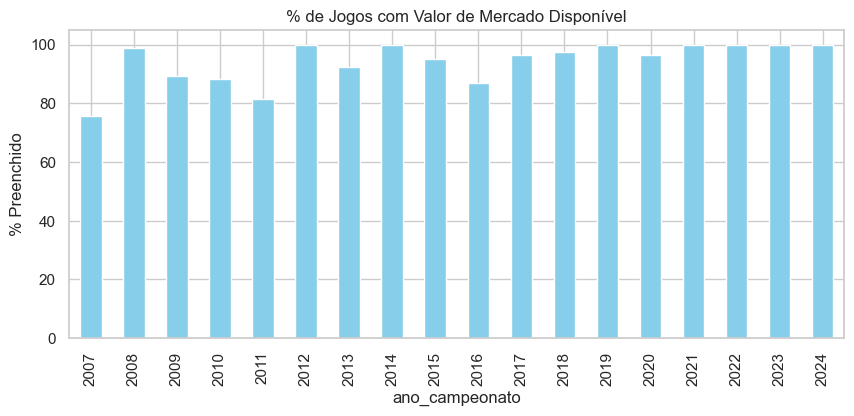

In [71]:
# Analisando a cobertura de dados financeiros por ano
financeiro_por_ano = df.groupby('ano_campeonato').apply(lambda x: x['valor_equipe_titular_mandante'].notnull().mean() * 100)
print("Porcentagem de dados financeiros presentes por ano:")
print(financeiro_por_ano)

# Plotando para visualização rápida
plt.figure(figsize=(10,4))
financeiro_por_ano.plot(kind='bar', color='skyblue')
plt.title('% de Jogos com Valor de Mercado Disponível')
plt.ylabel('% Preenchido')
plt.show()

In [72]:
df.columns

Index(['ano_campeonato', 'data', 'rodada', 'estadio', 'arbitro', 'publico',
       'publico_max', 'time_mandante', 'time_visitante', 'tecnico_mandante',
       'tecnico_visitante', 'colocacao_mandante', 'colocacao_visitante',
       'valor_equipe_titular_mandante', 'valor_equipe_titular_visitante',
       'idade_media_titular_mandante', 'idade_media_titular_visitante',
       'gols_mandante', 'gols_visitante', 'gols_1_tempo_mandante',
       'gols_1_tempo_visitante', 'defesas_visitante', 'chutes_fora_visitante'],
      dtype='object')

In [73]:
df.to_csv('../dados/raw/Investimento.csv')

In [74]:
pd.options.display.float_format = '{:.2f}'.format

In [75]:
df_invest = pd.read_csv('../dados/raw/Investimento.csv')

In [76]:
df_invest.head()

,Unnamed: 0,ano_campeonato,data,rodada,estadio,arbitro,publico,publico_max,time_mandante,time_visitante,...,valor_equipe_titular_mandante,valor_equipe_titular_visitante,idade_media_titular_mandante,idade_media_titular_visitante,gols_mandante,gols_visitante,gols_1_tempo_mandante,gols_1_tempo_visitante,defesas_visitante,chutes_fora_visitante
0,418,2016,2016-09-15,25,Estádio Olímpico Nilton Santos,Paulo Henrique Schleinch Vollkopf,11883.00,46931.00,Botafogo,Santos FC,...,8900000.00,28750000.00,28.50,27.40,0.00,1.00,NaN,NaN,NaN,NaN
1,419,2016,2016-09-25,27,Estádio Estadual Kléber José de Andrade,Leandro Pedro Vuaden,13780.00,NaN,Flamengo,Cruzeiro,...,26100000.00,31900000.00,28.40,27.50,2.00,1.00,NaN,NaN,NaN,NaN
2,420,2016,2016-10-09,29,Estádio Municipal Paulo Machado de Carvalho,Ricardo Marques Ribeiro,21773.00,78838.00,Flamengo,Santa Cruz,...,24850000.00,5750000.00,28.00,27.40,3.00,0.00,NaN,NaN,NaN,NaN
3,421,2016,2016-10-23,32,Estádio Jornalista Mário Filho,Anderson Daronco,54250.00,78838.00,Flamengo,Corinthians,...,27850000.00,22500000.00,29.50,27.50,2.00,2.00,NaN,NaN,NaN,NaN
4,422,2016,2016-10-13,30,Estádio General Sílvio Raulino de Oliveira,Sandro Ricci,9008.00,NaN,Fluminense,Flamengo,...,24250000.00,25100000.00,27.50,28.10,1.00,2.00,NaN,NaN,NaN,NaN


In [77]:
df_invest.columns

Index(['Unnamed: 0', 'ano_campeonato', 'data', 'rodada', 'estadio', 'arbitro',
       'publico', 'publico_max', 'time_mandante', 'time_visitante',
       'tecnico_mandante', 'tecnico_visitante', 'colocacao_mandante',
       'colocacao_visitante', 'valor_equipe_titular_mandante',
       'valor_equipe_titular_visitante', 'idade_media_titular_mandante',
       'idade_media_titular_visitante', 'gols_mandante', 'gols_visitante',
       'gols_1_tempo_mandante', 'gols_1_tempo_visitante', 'defesas_visitante',
       'chutes_fora_visitante'],
      dtype='object')

In [78]:
df_mandante = df_invest[['ano_campeonato','rodada','time_mandante','valor_equipe_titular_mandante']].rename(columns={
    'time_mandante': 'time',
    'valor_equipe_titular_mandante': 'valor_mercado'
})

df_visitante = df_invest[['ano_campeonato','rodada','time_visitante','valor_equipe_titular_visitante']].rename(columns={
    'time_visitante': 'time',
    'valor_equipe_titular_visitante': 'valor_mercado'
})

df_valor = pd.concat([df_mandante, df_visitante])

In [79]:
df_valor['temporada'] = df_valor['ano_campeonato']

In [80]:
df_valor_time = df_valor.groupby(['temporada','time']).agg({
    'valor_mercado': 'mean' 
}).reset_index()

In [81]:
df_valor_time.head()

,temporada,time,valor_mercado
0,2007,América-RN,NaN
1,2007,Atlético-MG,2700000.00
2,2007,Atlético-PR,2702272.73
3,2007,Botafogo,4553846.15
4,2007,Corinthians,5472916.67


In [82]:
# pelo head, logo na primeira linha pode se observar um valor nulo, vou ver quantos são ao total
df_valor_time['valor_mercado'].isna().sum()

2

In [83]:
# Filtra as linhas onde a coluna 'valor_mercado' é nula (NaN), e com o print vou poder saber quais os times 
nulos = df_valor_time[df_valor_time['valor_mercado'].isna()]

print(nulos)

    temporada            time  valor_mercado
0        2007      América-RN            NaN
91       2011  Figueirense FC            NaN


Observou-se a ausência de um time na temporada de 2007 (América de Natal),
último colocado com baixo investimento.

Considerando seu baixo impacto no desempenho geral e no padrão da relação
entre investimento e pontuação, optou-se por manter o dataset sem ajustes,
pois não compromete a análise estatística.


Não foi possível obter o valor de mercado do Figueirense  na temporada de 2011.
Optou-se por remover o registro para garantir a integridade da análise de correlação,
evitando a introdução de dados artificiais.

In [84]:
df_modelo = df_fato.groupby(['temporada','time']).agg({
    'pontos': 'sum',
    'saldo': 'sum',
    'vitoria': 'sum'
}).reset_index()

df_modelo = df_modelo.merge(df_valor_time, on=['temporada','time'], how='left')

In [85]:
df_modelo.head()

,temporada,time,pontos,saldo,vitoria,valor_mercado
0,2007,América-RN,17,-56,4,NaN
1,2007,Atlético-MG,55,12,15,2700000.00
2,2007,Atlético-PR,54,1,14,2702272.73
3,2007,Botafogo,55,4,14,4553846.15
4,2007,Corinthians,44,-10,10,5472916.67


In [86]:
df_modelo['valor_mercado'].isna().sum()

7

In [87]:
df_modelo.head()

,temporada,time,pontos,saldo,vitoria,valor_mercado
0,2007,América-RN,17,-56,4,NaN
1,2007,Atlético-MG,55,12,15,2700000.00
2,2007,Atlético-PR,54,1,14,2702272.73
3,2007,Botafogo,55,4,14,4553846.15
4,2007,Corinthians,44,-10,10,5472916.67


In [88]:
df_modelo = df_modelo.dropna(subset=['valor_mercado'])

In [89]:
df_modelo.head()

,temporada,time,pontos,saldo,vitoria,valor_mercado
1,2007,Atlético-MG,55,12,15,2700000.00
2,2007,Atlético-PR,54,1,14,2702272.73
3,2007,Botafogo,55,4,14,4553846.15
4,2007,Corinthians,44,-10,10,5472916.67
5,2007,Cruzeiro,60,15,18,6251612.90


In [90]:
df_modelo.tail()

,temporada,time,pontos,saldo,vitoria,valor_mercado
360,2024,Juventude,31,-10,7,875.17
361,2024,Palmeiras,55,25,16,10036.03
362,2024,RB Bragantino,31,-5,7,3703.21
363,2024,São Paulo,50,13,15,2925.36
364,2024,Vasco da Gama,37,-9,10,2938.14


In [91]:
# ==========================================================
# INTEGRAÇÃO DA TEMPORADA 2025 (dados de outraFonte / fato_desempenho.csv)
# ==========================================================
# Os valores de mercado de 2025 foram obtidos da ListaDeTimes.docx
val_2025 = {
    'Palmeiras': 238_750_000, 'Flamengo': 219_150_000,
    'Botafogo-RJ': 135_950_000, 'Corinthians': 123_250_000,
    'Internacional': 106_650_000, 'Gremio': 98_100_000,
    'Santos': 96_100_000, 'Atletico-MG': 93_700_000,
    'Bahia': 92_000_000, 'Cruzeiro': 89_550_000,
    'Vasco': 85_880_000, 'Sao Paulo': 80_650_000,
    'Fluminense': 73_600_000, 'Bragantino': 70_100_000,
    'Fortaleza': 47_850_000, 'Vitoria': 39_950_000,
    'Sport': 36_650_000, 'Ceara': 30_000_000,
    'Mirassol': 18_230_000, 'Juventude': 17_380_000,
}

# Verificar se 2025 está presente no fato
fato_all = pd.read_csv('../dados/processed/fato_desempenho.csv', encoding='latin1')
fato_all = fato_all[fato_all['temporada'] >= 2007].copy()
tem_2025 = 2025 in fato_all['temporada'].values

if tem_2025:
    print("2025 encontrado no fato_desempenho.csv — integrando...")
    
    fato_2025 = fato_all[fato_all['temporada'] == 2025].copy()
    
    # Reconstruir jogos de 2025 a partir da tabela fato
    jogos_2025 = []
    for rod in sorted(fato_2025['rodada'].unique()):
        rd = fato_2025[fato_2025['rodada'] == rod]
        casa = rd[rd['casa_fora'] == 'casa'].reset_index(drop=True)
        fora = rd[rd['casa_fora'] == 'fora'].reset_index(drop=True)
        for i in range(len(casa)):
            man = casa.loc[i, 'time']
            vis = casa.loc[i, 'adversario']
            away_row = fora[fora['time'] == vis]
            gols_vis = float(away_row.iloc[0]['gols_pro']) if len(away_row) > 0 else np.nan
            jogos_2025.append({
                'ano_campeonato': 2025, 'rodada': rod, 'temporada': 2025,
                'time_mandante': man, 'time_visitante': vis,
                'gols_mandante': float(casa.loc[i, 'gols_pro']),
                'gols_visitante': gols_vis,
                'valor_equipe_titular_mandante': val_2025.get(man, np.nan),
                'valor_equipe_titular_visitante': val_2025.get(vis, np.nan),
            })
    
    df_2025_inv = pd.DataFrame(jogos_2025)
    
    # Unir valores: fontes originais (2007-2024) + 2025
    vals_25_man = df_2025_inv[['temporada', 'time_mandante', 'valor_equipe_titular_mandante']].rename(
        columns={'time_mandante': 'time', 'valor_equipe_titular_mandante': 'valor_mercado'})
    vals_25_vis = df_2025_inv[['temporada', 'time_visitante', 'valor_equipe_titular_visitante']].rename(
        columns={'time_visitante': 'time', 'valor_equipe_titular_visitante': 'valor_mercado'})
    df_valor_25 = pd.concat([vals_25_man, vals_25_vis], ignore_index=True)
    
    # Recalcular df_valor_time com 2007-2025
    df_valor_all = pd.concat([df_valor, df_valor_25], ignore_index=True)
    df_valor_time = df_valor_all.groupby(['temporada', 'time']).agg(
        valor_mercado=('valor_mercado', 'mean')
    ).reset_index().dropna(subset=['valor_mercado'])
else:
    print("2025 NAO encontrado no fato_desempenho.csv. Usando dados 2007-2024.")
    print("Execute outraFonte.ipynb para adicionar 2025 e rode este notebook novamente.")
    df_valor_all = df_valor.copy()
    df_valor_time = df_valor_all.groupby(['temporada', 'time']).agg(
        valor_mercado=('valor_mercado', 'mean')
    ).reset_index().dropna(subset=['valor_mercado'])

# Recalcular df_modelo
df_perf = fato_all[fato_all['temporada'] != 2025].groupby(['temporada', 'time']).agg(
    pontos=('pontos', 'sum'),
    saldo=('saldo', 'sum'),
    vitoria=('vitoria', 'sum')
).reset_index()

if tem_2025:
    df_perf_25 = fato_all[fato_all['temporada'] == 2025].groupby(['temporada', 'time']).agg(
        pontos=('pontos', 'sum'),
        saldo=('saldo', 'sum'),
        vitoria=('vitoria', 'sum')
    ).reset_index()
    df_perf = pd.concat([df_perf, df_perf_25], ignore_index=True)

df_modelo = df_perf.merge(df_valor_time, on=['temporada', 'time'], how='left')
df_modelo = df_modelo.dropna(subset=['valor_mercado'])

# Rankings
df_modelo['rank_performance'] = df_modelo.groupby('temporada')['pontos'].rank(method='min', ascending=False)
df_modelo['rank_financeiro'] = df_modelo.groupby('temporada')['valor_mercado'].rank(method='min', ascending=False)
df_modelo['no_g4_real'] = (df_modelo['rank_performance'] <= 4).astype(int)
df_modelo['no_g4_financeiro'] = (df_modelo['rank_financeiro'] <= 4).astype(int)
df_modelo['destaque_gestao'] = df_modelo.apply(lambda r: 'Duo Dominante (Fla/Pal)' if r['temporada'] >= 2018 and r['time'] in ['Flamengo', 'Palmeiras'] else 'Outros', axis=1)

print(f"df_modelo: {df_modelo.shape}")
print(f"Temporadas: {sorted(df_modelo['temporada'].unique())}")
print(df_modelo.groupby('temporada').size())

2025 encontrado no fato_desempenho.csv — integrando...
df_modelo: (251, 11)
Temporadas: [2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
temporada
2007    12
2008    13
2009    11
2010    11
2011    11
2012    15
2013    12
2014    13
2015    14
2016    14
2017    13
2018    12
2019    14
2020    14
2021    13
2022    12
2023    14
2024    13
2025    20
dtype: int64


In [92]:
df_modelo.head()

,temporada,time,pontos,saldo,vitoria,valor_mercado,rank_performance,rank_financeiro,no_g4_real,no_g4_financeiro,destaque_gestao
6,2007,Botafogo,55,4,14,4553846.15,6.00,8.00,0,0,Outros
8,2007,Corinthians,44,-10,10,5472916.67,11.00,7.00,0,0,Outros
9,2007,Cruzeiro,60,15,18,6251612.90,4.00,6.00,1,0,Outros
11,2007,Figueirense FC,53,1,14,3170967.74,9.00,9.00,0,0,Outros
12,2007,Flamengo,61,6,17,8558064.52,2.00,4.00,1,1,Outros


In [93]:
df_modelo.tail()

,temporada,time,pontos,saldo,vitoria,valor_mercado,rank_performance,rank_financeiro,no_g4_real,no_g4_financeiro,destaque_gestao
604,2025,Santos,47,-5,12,96100000.00,12.00,7.00,0,0,Outros
605,2025,Sao Paulo,51,-4,14,80650000.00,8.00,12.00,0,0,Outros
606,2025,Sport,17,-47,2,36650000.00,20.00,17.00,0,0,Outros
607,2025,Vasco,45,-5,13,85880000.00,14.00,11.00,0,0,Outros
608,2025,Vitoria,45,-17,11,39950000.00,14.00,16.00,0,0,Outros


### Evento de ruptura
   Antes de 2018, o Brasileirão era conhecido pela sua extrema alternância (o "qualquer um ganha"). A organização desses dois clubes mudou o comportamento da  variável pontos em relação ao valor_mercado: o dinheiro passou a ser convertido em pontos de forma muito mais eficiente e previsível.

In [94]:
#fazendo a correlação de pearson sobre o valor de mercado 
from scipy.stats import pearsonr

corr, p_value = pearsonr(df_modelo['valor_mercado'], df_modelo['pontos'])

print(corr, p_value)

0.3263898772366005 1.2179601842653334e-07


In [95]:
# 1. Definir os rankings por temporada
df_modelo['rank_performance'] = df_modelo.groupby('temporada')['pontos'].rank(method='min', ascending=False)
df_modelo['rank_financeiro'] = df_modelo.groupby('temporada')['valor_mercado'].rank(method='min', ascending=False)

# 2. Criar colunas binárias (1 se for Top 4, 0 se não)
df_modelo['no_g4_real'] = (df_modelo['rank_performance'] <= 4).astype(int)
df_modelo['no_g4_financeiro'] = (df_modelo['rank_financeiro'] <= 4).astype(int)

# 3. Calcular a Matrix de Confusão / Eficiência
# Quantas vezes o Top 4 financeiro REALMENTE terminou no G4?
sucesso_investimento = df_modelo[df_modelo['no_g4_financeiro'] == 1]['no_g4_real'].mean() * 100

print(f"Eficiência do Capital: {sucesso_investimento:.1f}% dos times do Top 4 financeiro garantiram vaga na Libertadores.")

Eficiência do Capital: 59.2% dos times do Top 4 financeiro garantiram vaga na Libertadores.


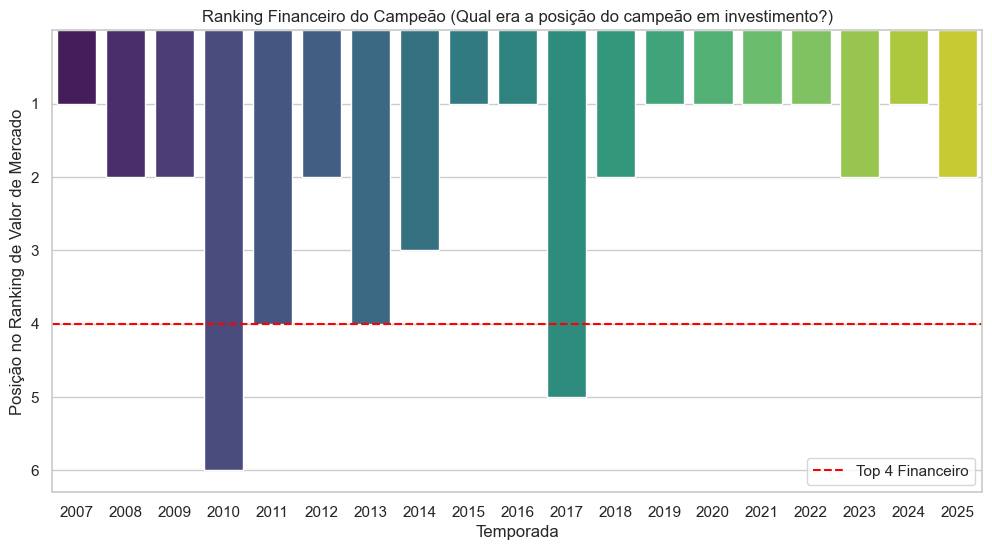

In [96]:
# 1. Definir o ranking de pontos (posicao final) e o ranking financeiro por temporada
# Usamos o método 'rank' com 'ascending=False' para que o maior valor seja 1º
df_modelo['rank_final'] = df_modelo.groupby('temporada')[['pontos', 'vitoria', 'saldo']].apply(
    lambda x: x.sort_values(['pontos', 'vitoria', 'saldo'], ascending=False)
).index.get_level_values(1) # Este passo é complexo, vamos simplificar:

# Forma mais simples de garantir os rankings:
df_modelo['rank_performance'] = df_modelo.groupby('temporada')['pontos'].rank(method='min', ascending=False)
df_modelo['rank_financeiro'] = df_modelo.groupby('temporada')['valor_mercado'].rank(method='min', ascending=False)

# 2. Filtrar apenas os campeões (rank_performance == 1)
# Obs: Em caso de empate exato em tudo, pegamos o primeiro
campeoes = df_modelo.sort_values(['temporada', 'pontos', 'vitoria', 'saldo'], ascending=[True, False, False, False])
campeoes = campeoes.groupby('temporada').head(1)

# 3. Preparar o gráfico do ranking financeiro dos campeões
plt.figure(figsize=(12, 6))
sns.barplot(data=campeoes, x='temporada', y='rank_financeiro', palette='viridis')

plt.axhline(y=4, color='red', linestyle='--', label='Top 4 Financeiro')
plt.title('Ranking Financeiro do Campeão (Qual era a posição do campeão em investimento?)')
plt.ylabel('Posição no Ranking de Valor de Mercado')
plt.xlabel('Temporada')
plt.gca().invert_yaxis() # Inverter para o 1º ficar no topo
plt.yticks(range(1, int(campeoes['rank_financeiro'].max()) + 1))
plt.legend()
plt.show()

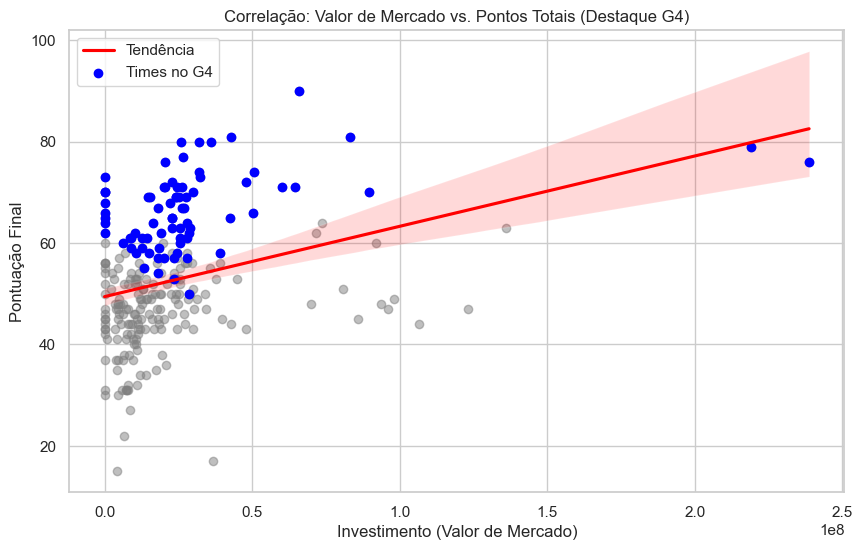

In [97]:
plt.figure(figsize=(10, 6))
sns.regplot(data=df_modelo, x='valor_mercado', y='pontos', 
            scatter_kws={'alpha':0.5, 'color':'gray'}, 
            line_kws={'color':'red', 'label':'Tendência'})

# Destacar quem ficou no G4
g4_plot = df_modelo[df_modelo['no_g4_real'] == 1]
plt.scatter(g4_plot['valor_mercado'], g4_plot['pontos'], color='blue', label='Times no G4')

plt.title('Correlação: Valor de Mercado vs. Pontos Totais (Destaque G4)')
plt.xlabel('Investimento (Valor de Mercado)')
plt.ylabel('Pontuação Final')
plt.legend()
plt.show()

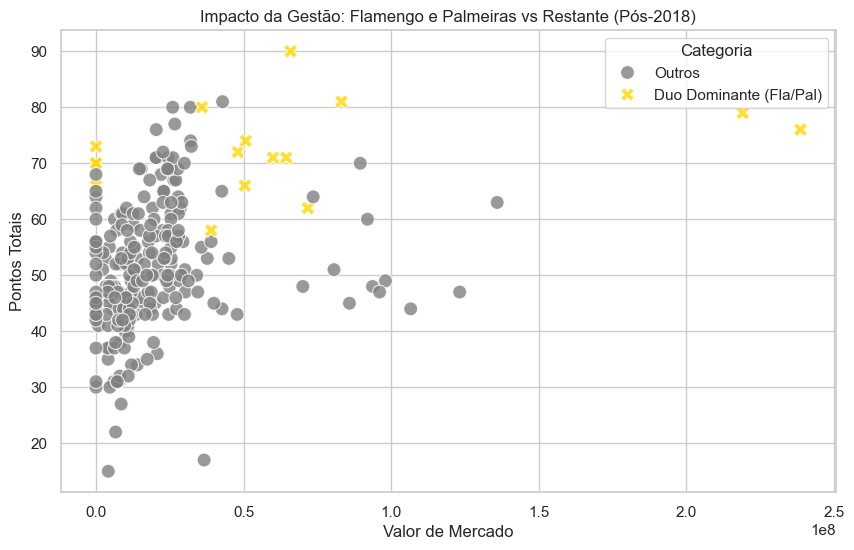

In [98]:
# Boa gestão e seus resultados 
def destacar_dominancia(row):
    # Filtro para o período de hegemonia e os clubes específicos
    if row['temporada'] >= 2018 and row['time'] in ['Flamengo', 'Palmeiras']:
        return 'Duo Dominante (Fla/Pal)'
    return 'Outros'

# 2. Aplicando a função corrigida (destacar_dominancia)
df_modelo['destaque_gestao'] = df_modelo.apply(destacar_dominancia, axis=1)

# 3. Gerando o gráfico para visualizar o "Salto de Patamar"
plt.figure(figsize=(10,6))
sns.scatterplot(data=df_modelo, x='valor_mercado', y='pontos', 
                hue='destaque_gestao', style='destaque_gestao', 
                palette={'Duo Dominante (Fla/Pal)': 'gold', 'Outros': 'gray'},
                s=100, alpha=0.8)

plt.title('Impacto da Gestão: Flamengo e Palmeiras vs Restante (Pós-2018)')
plt.xlabel('Valor de Mercado')
plt.ylabel('Pontos Totais')
plt.legend(title='Categoria')
plt.show()

In [99]:
# ==========================================================
# CORRELAÇÃO PEARSON EM 3 PERÍODOS
# ==========================================================

# FASE 1: População completa (2007-2025)
corr_tot, p_tot = pearsonr(df_modelo['valor_mercado'], df_modelo['pontos'])
print(f'=== FASE 1: População completa (2007-2025) ===')
print(f'Pearson r = {corr_tot:.4f}')
print(f'p-value   = {p_tot:.2e}')
print(f'n         = {len(df_modelo)}')
print()

# FASE 2: Pré-ruptura (2007-2017)
df_pre = df_modelo[df_modelo['temporada'] <= 2017]
corr_pre, p_pre = pearsonr(df_pre['valor_mercado'], df_pre['pontos'])
print(f'=== FASE 2: Pré-ruptura (2007-2017) ===')
print(f'Pearson r = {corr_pre:.4f}')
print(f'p-value   = {p_pre:.2e}')
print(f'n         = {len(df_pre)}')
print()

# FASE 3: Pós-ruptura (2018-2025)
df_pos = df_modelo[df_modelo['temporada'] >= 2018]
corr_pos, p_pos = pearsonr(df_pos['valor_mercado'], df_pos['pontos'])
print(f'=== FASE 3: Pós-ruptura (2018-2025) ===')
print(f'Pearson r = {corr_pos:.4f}')
print(f'p-value   = {p_pos:.2e}')
print(f'n         = {len(df_pos)}')

=== FASE 1: População completa (2007-2025) ===
Pearson r = 0.3264
p-value   = 1.22e-07
n         = 251

=== FASE 2: Pré-ruptura (2007-2017) ===
Pearson r = 0.5421
p-value   = 5.50e-12
n         = 139

=== FASE 3: Pós-ruptura (2018-2025) ===
Pearson r = 0.3431
p-value   = 2.13e-04
n         = 112


In [100]:
# ==========================================================
# TESTES DE HIPÓTESE  —  Investimento vs Pontos
# ==========================================================
from scipy.stats import norm

print("=== TESTE 1: r > 0 em cada período (Fisher z one-tail) ===")
for label, r, p, n in [
    ('Completo', corr_tot, p_tot, len(df_modelo)),
    ('Pré-ruptura', corr_pre, p_pre, len(df_pre)),
    ('Pós-ruptura', corr_pos, p_pos, len(df_pos)),
]:
    z = np.arctanh(r)
    se = 1 / np.sqrt(n - 3)
    z_stat = z / se
    p1 = 1 - norm.cdf(z_stat)  # one-tail
    sig = 'SIM' if p1 < 0.05 else 'NÃO'
    print(f'{label}: r={r:.4f}, z={z_stat:.3f}, p={p1:.2e} → Rejeita H0? {sig}')

print()
print("=== TESTE 2: r_pós > r_pré? (Fisher z-test para diferença entre correlações) ===")
z_pre = np.arctanh(corr_pre)
z_pos = np.arctanh(corr_pos)
se_diff = np.sqrt(1/(len(df_pre) - 3) + 1/(len(df_pos) - 3))
z_diff = (z_pos - z_pre) / se_diff
p_diff = 1 - norm.cdf(z_diff)
print(f'z_pre = {z_pre:.4f} (r={corr_pre:.4f})')
print(f'z_pos = {z_pos:.4f} (r={corr_pos:.4f})')
print(f'z_diff = {z_diff:.4f}, p_one-tail = {p_diff:.4f}')
print(f'A correlação aumentou significativamente após 2018? {"SIM" if p_diff < 0.05 else "NÃO"} (α=0.05)')

=== TESTE 1: r > 0 em cada período (Fisher z one-tail) ===
Completo: r=0.3264, z=5.335, p=4.77e-08 → Rejeita H0? SIM
Pré-ruptura: r=0.5421, z=7.080, p=7.21e-13 → Rejeita H0? SIM
Pós-ruptura: r=0.3431, z=3.733, p=9.44e-05 → Rejeita H0? SIM

=== TESTE 2: r_pós > r_pré? (Fisher z-test para diferença entre correlações) ===
z_pre = 0.6071 (r=0.5421)
z_pos = 0.3576 (r=0.3431)
z_diff = -1.9408, p_one-tail = 0.9739
A correlação aumentou significativamente após 2018? NÃO (α=0.05)


In [101]:
# Teste: Campeões tendem a ser do Top 4 financeiro?
from scipy.stats import ttest_1samp

campeoes = df_modelo.sort_values(['temporada', 'pontos', 'vitoria', 'saldo'],
                                  ascending=[True, False, False, False])
campeoes = campeoes.groupby('temporada').head(1).copy()
campeoes['top4_fin'] = (campeoes['rank_financeiro'] <= 4).astype(int)

pct = campeoes['top4_fin'].mean() * 100
# Teste t one-tail vs proporção aleatória de 50%
t_stat, p_val = ttest_1samp(campeoes['top4_fin'], 0.5)
p_one = p_val / 2 if t_stat > 0 else 1 - p_val / 2

print("=== TESTE 3: Campeões estão no Top 4 financeiro? ===")
print(f"Campeões no Top 4: {campeoes['top4_fin'].sum()}/{len(campeoes)} ({pct:.1f}%)")
print(f't = {t_stat:.3f}, p_one-tail = {p_one:.4f}')
print(f"Significativo? {'SIM' if p_one < 0.05 else 'NÃO'}")

# Binomial test
import scipy.stats as stats
binom_p = 1 - stats.binom.cdf(campeoes['top4_fin'].sum() - 1, len(campeoes), 0.20)
print(f'Teste binomial (H0: 20% aleatório): {binom_p:.4f}')

=== TESTE 3: Campeões estão no Top 4 financeiro? ===
Campeões no Top 4: 17/19 (89.5%)
t = 5.457, p_one-tail = 0.0000
Significativo? SIM
Teste binomial (H0: 20% aleatório): 0.0000


In [102]:
# GERAR CSV ANÁLISE DE INVESTIMENTO PARA POWER BI
df_bi = df_modelo[[
    'temporada', 'time', 'pontos', 'saldo', 'vitoria',
    'valor_mercado', 'rank_performance', 'rank_financeiro',
    'no_g4_real', 'no_g4_financeiro', 'destaque_gestao'
]].copy()
df_bi.to_csv('../dados/processed/investimento_vs_desempenho.csv', index=False, sep=';', encoding='utf-8')

print(f'investimento_vs_desempenho.csv salvo: {df_bi.shape}')
print(df_bi.head())
print()
print('Resumo dos campeões:')
print(campeoes[['temporada', 'time', 'pontos', 'rank_financeiro', 'top4_fin']].to_string())

investimento_vs_desempenho.csv salvo: (251, 11)
    temporada            time  pontos  saldo  vitoria  valor_mercado  \
6        2007        Botafogo      55      4       14     4553846.15   
8        2007     Corinthians      44    -10       10     5472916.67   
9        2007        Cruzeiro      60     15       18     6251612.90   
11       2007  Figueirense FC      53      1       14     3170967.74   
12       2007        Flamengo      61      6       17     8558064.52   

    rank_performance  rank_financeiro  no_g4_real  no_g4_financeiro  \
6               6.00             8.00           0                 0   
8              11.00             7.00           0                 0   
9               4.00             6.00           1                 0   
11              9.00             9.00           0                 0   
12              2.00             4.00           1                 1   

   destaque_gestao  
6           Outros  
8           Outros  
9           Outros  
11      

## Tese do Guardiola

  A tese do técnico Pepe Guardiola consiste em que se ganha títulos nas 8 últimas rodadas, mas você perde eles nas 8 primeiras, nesta sessão 
vamos analisar se essa tese se aplica aqui no Brasil.

In [103]:
df.drop(columns=['colunas_que_talvez_nao_existam'], errors='ignore', inplace=True)

In [104]:
# ==========================================================
# TESE DA 8ª RODADA (Guardiola)
# ==========================================================
# Função para gerar classificação a partir de um df no formato
# com colunas: time, pontos, gols_pro, gols_contra
def gerar_classificacao_simples(df_periodo):
    tabela = df_periodo.groupby('time').agg(
        pts=('pontos', 'sum'),
        gp=('gols_pro', 'sum'),
        gc=('gols_contra', 'sum')
    )
    tabela['sg'] = tabela['gp'] - tabela['gc']
    return tabela.sort_values(by=['pts', 'sg', 'gp'], ascending=False)

resultados = []

# Para os anos 2007-2024, usar Investment.csv
df_orig = pd.read_csv('../dados/raw/Investimento.csv')
df_orig = df_orig[df_orig['ano_campeonato'] >= 2007].copy()
df_orig['pontos_m'] = np.where(
    df_orig['gols_mandante'] > df_orig['gols_visitante'], 3,
    np.where(df_orig['gols_mandante'] == df_orig['gols_visitante'], 1, 0))
df_orig['pontos_v'] = np.where(
    df_orig['gols_visitante'] > df_orig['gols_mandante'], 3,
    np.where(df_orig['gols_visitante'] == df_orig['gols_mandante'], 1, 0))

for ano in sorted(df_orig['ano_campeonato'].unique()):
    df_ano = df_orig[df_orig['ano_campeonato'] == ano]
    m = df_ano[['rodada','time_mandante','pontos_m','gols_mandante','gols_visitante']].rename(
        columns={'time_mandante': 'time', 'pontos_m': 'pontos', 'gols_mandante': 'gols_pro', 'gols_visitante': 'gols_contra'})
    v = df_ano[['rodada','time_visitante','pontos_v','gols_visitante','gols_mandante']].rename(
        columns={'time_visitante': 'time', 'pontos_v': 'pontos', 'gols_visitante': 'gols_pro', 'gols_mandante': 'gols_contra'})
    df_ano_all = pd.concat([m, v], ignore_index=True)
    
    t_r8 = gerar_classificacao_simples(df_ano_all[df_ano_all['rodada'] <= 8])
    if len(t_r8) == 0:
        continue
    lider_r8 = t_r8.index[0]
    pts_r8 = t_r8.iloc[0]['pts']
    t_fin = gerar_classificacao_simples(df_ano_all)
    campeao_fin = t_fin.index[0]
    pos_fin = t_fin.index.get_loc(lider_r8) + 1
    aprov_r8 = (pts_r8 / 24) * 100
    resultados.append({
        'temporada': ano, 'lider_r8': lider_r8, 'pts_r8': pts_r8,
        'aproveitamento_r8': aprov_r8, 'campeao': campeao_fin,
        'pos_final_lider_r8': pos_fin,
        'tese_confirmada': 1 if lider_r8 == campeao_fin else 0
    })

# Processar 2025 a partir do fato_desempenho.csv
fato_25_r8 = pd.read_csv('../dados/processed/fato_desempenho.csv', encoding='latin1')
fato_25_r8 = fato_25_r8[fato_25_r8['temporada'] == 2025].copy()
if len(fato_25_r8) > 0:
    print("Processando 2025 para a Tese R8...")
    t_r8_25 = gerar_classificacao_simples(fato_25_r8[fato_25_r8['rodada'] <= 8])
    t_fin_25 = gerar_classificacao_simples(fato_25_r8)
    
    if len(t_r8_25) > 0 and len(t_fin_25) > 0:
        lider_r8_25 = t_r8_25.index[0]
        pts_r8_25 = t_r8_25.iloc[0]['pts']
        campeao_25 = t_fin_25.index[0]
        pos_fin_25 = t_fin_25.index.get_loc(lider_r8_25) + 1
        aprov_r8_25 = (pts_r8_25 / 24) * 100
        resultados.append({
            'temporada': 2025, 'lider_r8': lider_r8_25, 'pts_r8': pts_r8_25,
            'aproveitamento_r8': aprov_r8_25, 'campeao': campeao_25,
            'pos_final_lider_r8': pos_fin_25,
            'tese_confirmada': 1 if lider_r8_25 == campeao_25 else 0
        })
        print(f"  2025: Lider R8 = {lider_r8_25} ({pts_r8_25} pts), Campeao = {campeao_25}, Posicao Final = {pos_fin_25}")

df_validacao = pd.DataFrame(resultados)
df_validacao['periodo'] = np.where(
    df_validacao['temporada'] <= 2017, 'Pre-ruptura (2007-2017)',
    'Pos-ruptura (2018-2025)')

# Teste binomial — Líder R8 no Top 4
top4_count = (df_validacao['pos_final_lider_r8'] <= 4).sum()
total = len(df_validacao)
binom_p_top4 = 1 - stats.binom.cdf(top4_count - 1, total, 0.20)

print(f'Teste binomial — Líder R8 no Top 4: {top4_count}/{total} ({top4_count/total*100:.1f}%)')
print(f'p_one-tail (H0: 20% aleatório) = {binom_p_top4:.4f}')
print(f"Significativo? {'SIM' if binom_p_top4 < 0.05 else 'NÃO'}")

# Resumo por período
for periodo, df_v in df_validacao.groupby('periodo'):
    teses = df_v['tese_confirmada'].sum()
    total_p = len(df_v)
    print(f"\n{periodo}: Tese confirmada {teses}/{total_p} ({teses/total_p*100:.1f}%)")

Processando 2025 para a Tese R8...
  2025: Lider R8 = Palmeiras (19 pts), Campeao = Flamengo, Posicao Final = 2
Teste binomial — Líder R8 no Top 4: 11/19 (57.9%)
p_one-tail (H0: 20% aleatório) = 0.0003
Significativo? SIM

Pos-ruptura (2018-2025): Tese confirmada 1/8 (12.5%)

Pre-ruptura (2007-2017): Tese confirmada 3/11 (27.3%)


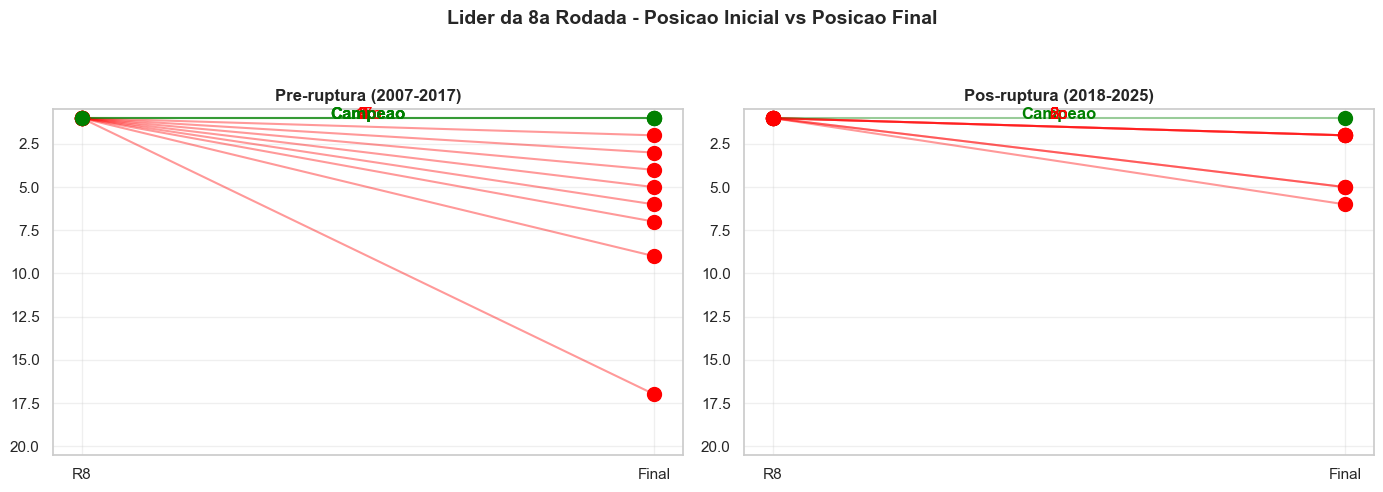


tese_r8_guardiola.csv salvo: (19, 8)
    temporada       lider_r8  pts_r8  aproveitamento_r8      campeao  pos_final_lider_r8  tese_confirmada                  periodo
0        2007       Botafogo   17.00              70.83    São Paulo                   9                0  Pre-ruptura (2007-2017)
1        2008       Flamengo   19.00              79.17    São Paulo                   5                0  Pre-ruptura (2007-2017)
2        2009    Atlético-MG   17.00              70.83     Flamengo                   7                0  Pre-ruptura (2007-2017)
3        2010    Corinthians   18.00              75.00   Fluminense                   3                0  Pre-ruptura (2007-2017)
4        2011    Corinthians   20.00              83.33  Corinthians                   1                1  Pre-ruptura (2007-2017)
5        2012    Atlético-MG   19.00              79.17   Fluminense                   2                0  Pre-ruptura (2007-2017)
6        2013       Botafogo   16.00         

In [105]:
# Gráfico: Líder R8 - Posição Inicial vs Final por período
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, df_v, titulo in [
    (axes[0], df_validacao[df_validacao['temporada'] <= 2017], 'Pre-ruptura (2007-2017)'),
    (axes[1], df_validacao[df_validacao['temporada'] >= 2018], 'Pos-ruptura (2018-2025)')
]:
    for _, row in df_v.iterrows():
        cor = 'green' if row['tese_confirmada'] == 1 else 'red'
        ax.scatter(['R8', 'Final'], [1, row['pos_final_lider_r8']], color=cor, s=100, zorder=3)
        ax.plot(['R8', 'Final'], [1, row['pos_final_lider_r8']], color=cor, alpha=0.4)
        if row['tese_confirmada'] == 1:
            ax.annotate('Campeao', xy=(0.5, 1.05), ha='center', color='green', fontweight='bold')
        else:
            ax.annotate(f"{row['pos_final_lider_r8']}o", xy=(0.5, 1.05), ha='center', color='red')
    ax.set_ylim(20.5, 0.5)
    ax.set_title(titulo, fontweight='bold')
    ax.grid(True, alpha=0.3)
fig.suptitle('Lider da 8a Rodada - Posicao Inicial vs Posicao Final', fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

# GERAR CSV TESE DA 8ª RODADA PARA POWER BI
df_r8_bi = df_validacao[[
    'temporada', 'lider_r8', 'pts_r8', 'aproveitamento_r8',
    'campeao', 'pos_final_lider_r8', 'tese_confirmada', 'periodo'
]].copy()
df_r8_bi.to_csv('../dados/processed/tese_r8_guardiola.csv', index=False, sep=';', encoding='utf-8')
print(f'\ntese_r8_guardiola.csv salvo: {df_r8_bi.shape}')
print(df_r8_bi.to_string())

In [ ]:
# ==========================================================
# INTERVALOS DE CONFIANÇA — Dashboard 3 (Tese do Guardiola)
# ==========================================================
# Recarrega o CSV salvo e adiciona colunas de IC (95%)
# Os valores são repetidos em todas as linhas para uso como
# cartões no Power BI via medidas MAX/MIN.
import numpy as np
from scipy import stats
import pandas as pd

df_ic = pd.read_csv('../dados/processed/tese_r8_guardiola.csv', sep=';', encoding='utf-8')
n = len(df_ic)
alpha = 0.05

# --- IC 1: Proporção (Wilson score) — taxa de confirmação da tese ---
p_hat = df_ic['tese_confirmada'].mean()
z = stats.norm.ppf(1 - alpha / 2)
denom = 1 + z**2 / n
center = (p_hat + z**2 / (2 * n)) / denom
margin = (z * np.sqrt(p_hat * (1 - p_hat) / n + z**2 / (4 * n**2))) / denom
ic_prop_lower = round((center - margin) * 100, 1)
ic_prop_upper = round((center + margin) * 100, 1)
print(f'IC Proporção (Wilson 95%): [{ic_prop_lower}%, {ic_prop_upper}%]')

# --- IC 2: Correlação de Pearson (Fisher z-transform) ---
# aproveitamento_r8 vs pos_final_lider_r8
r, _ = stats.pearsonr(df_ic['aproveitamento_r8'], df_ic['pos_final_lider_r8'])
z_r = np.arctanh(r)
se_r = 1 / np.sqrt(n - 3)
ic_r_lower = round(np.tanh(z_r - z * se_r), 4)
ic_r_upper = round(np.tanh(z_r + z * se_r), 4)
print(f'IC Correlação Pearson (Fisher 95%): r={r:.4f}, IC=[{ic_r_lower}, {ic_r_upper}]')

# --- IC 3: Posição final média do líder da R8 (t de Student) ---
pos_mean = df_ic['pos_final_lider_r8'].mean()
pos_se = df_ic['pos_final_lider_r8'].sem()
t_crit = stats.t.ppf(1 - alpha / 2, df=n - 1)
ic_pos_lower = round(pos_mean - t_crit * pos_se, 2)
ic_pos_upper = round(pos_mean + t_crit * pos_se, 2)
print(f'IC Posição Final Média (t 95%): média={pos_mean:.2f}, IC=[{ic_pos_lower}, {ic_pos_upper}]')

# --- Adiciona colunas ao CSV ---
df_ic['ic_prop_lower']  = ic_prop_lower
df_ic['ic_prop_upper']  = ic_prop_upper
df_ic['ic_r_lower']     = ic_r_lower
df_ic['ic_r_upper']     = ic_r_upper
df_ic['ic_pos_lower']   = ic_pos_lower
df_ic['ic_pos_upper']   = ic_pos_upper

df_ic.to_csv('../dados/processed/tese_r8_guardiola.csv', index=False, sep=';', encoding='utf-8')
print(f'
tese_r8_guardiola.csv atualizado com ICs: {df_ic.shape}')
